      38    |    6.500
      15    |   10.346
      20    |    8.960
      25    |    8.014
      30    |    7.316
      35    |    6.773
      40    |    6.335
      45    |    5.973
CSV outfile: /data_fast/Work/MS_HF_cohort/images/AveirVR/RV_Collision//sum_plots/RV_septum_polar_sum_AveirVR_L38.csv
CSV outfile: /data_fast/Work/MS_HF_cohort/images/AveirVR/TV_Collision//sum_plots/RV_septum_polar_sum_AveirVR_L38.csv
CSV outfile: /data_fast/Work/MS_HF_cohort/images/AveirVR/PM_Collision//sum_plots/RV_septum_polar_sum_AveirVR_L38.csv
CSV outfile: /data_fast/Work/MS_HF_cohort/images/AveirVR//sum_plots/RV_septum_polar_sum_AveirVR_L38.csv
CSV outfile: /data_fast/Work/MS_HF_cohort/images/AveirVR/RV_Collision//sum_plots/RV_septum_polar_sum_AveirVR_L15.csv
CSV outfile: /data_fast/Work/MS_HF_cohort/images/AveirVR/TV_Collision//sum_plots/RV_septum_polar_sum_AveirVR_L15.csv
CSV outfile: /data_fast/Work/MS_HF_cohort/images/AveirVR/PM_Collision//sum_plots/RV_septum_polar_sum_AveirVR_L15.csv
CSV outfil

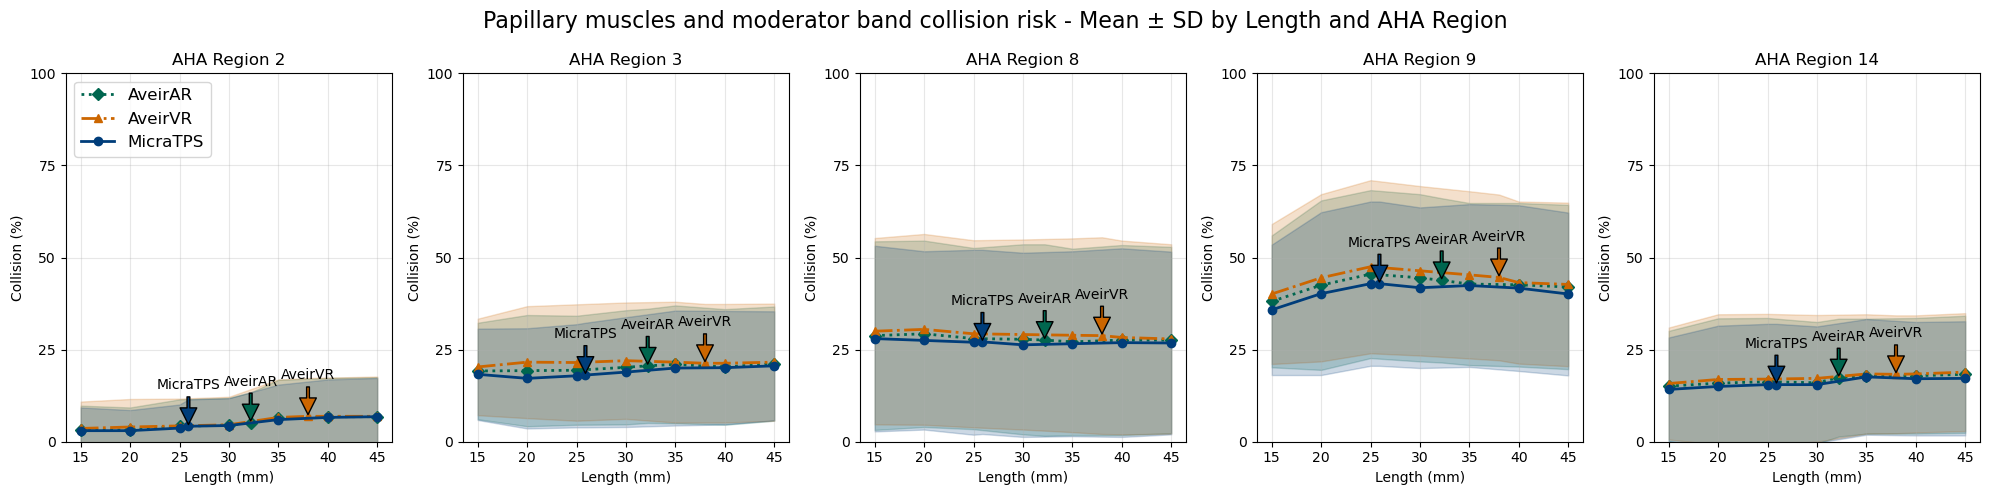

Axes(0.125,0.11;0.133621x0.77)


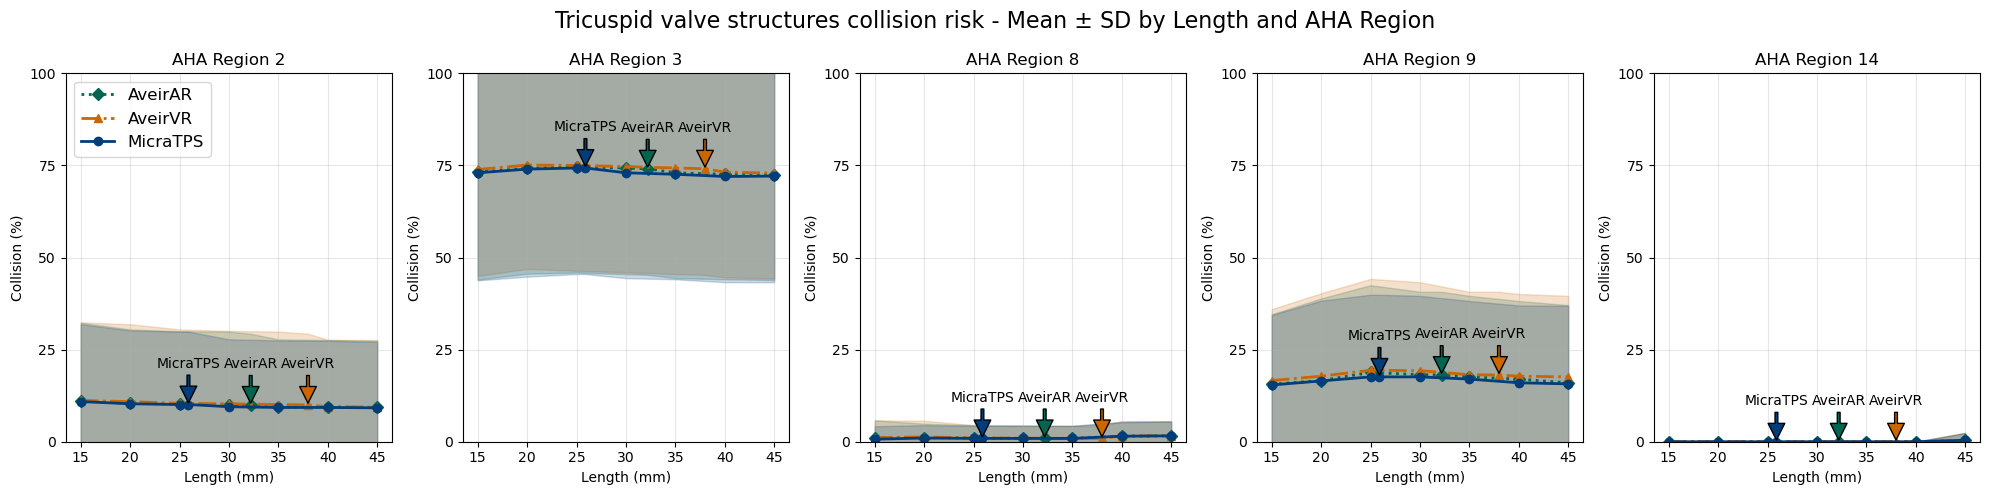

Axes(0.125,0.11;0.133621x0.77)


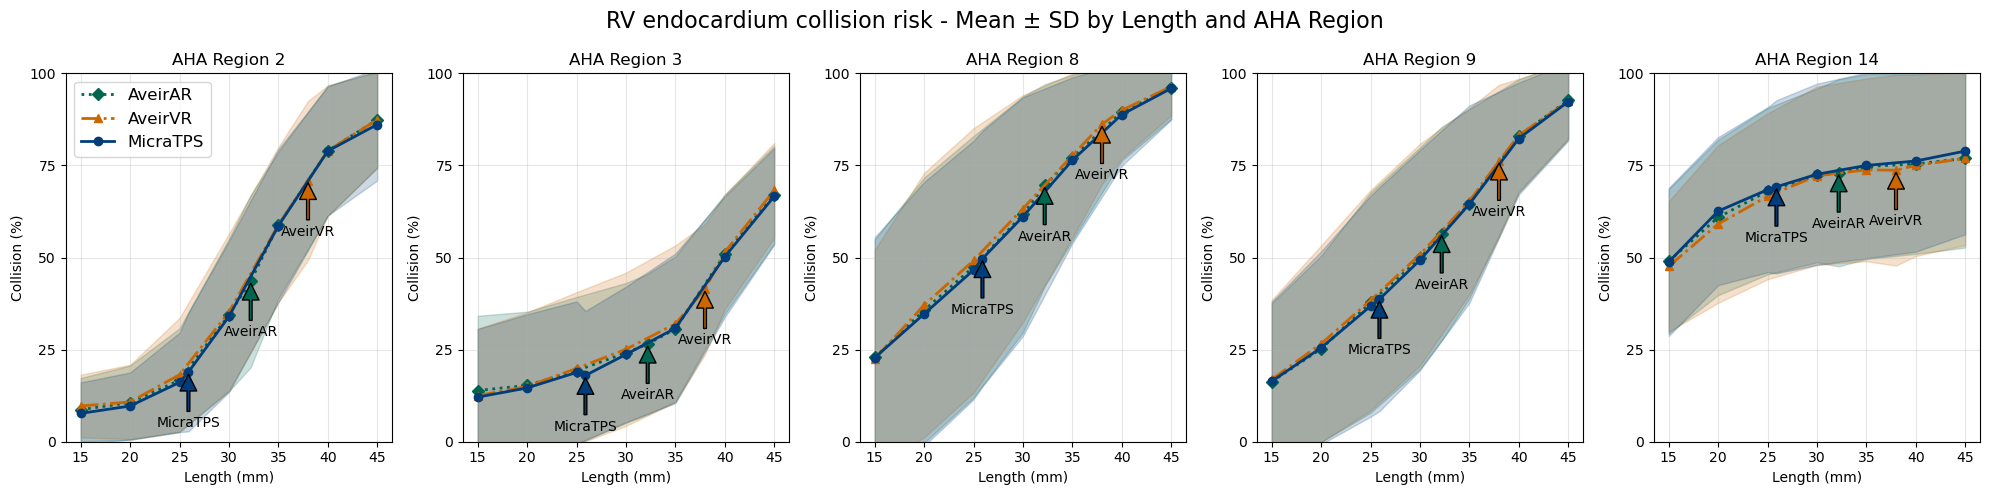

Axes(0.125,0.11;0.133621x0.77)


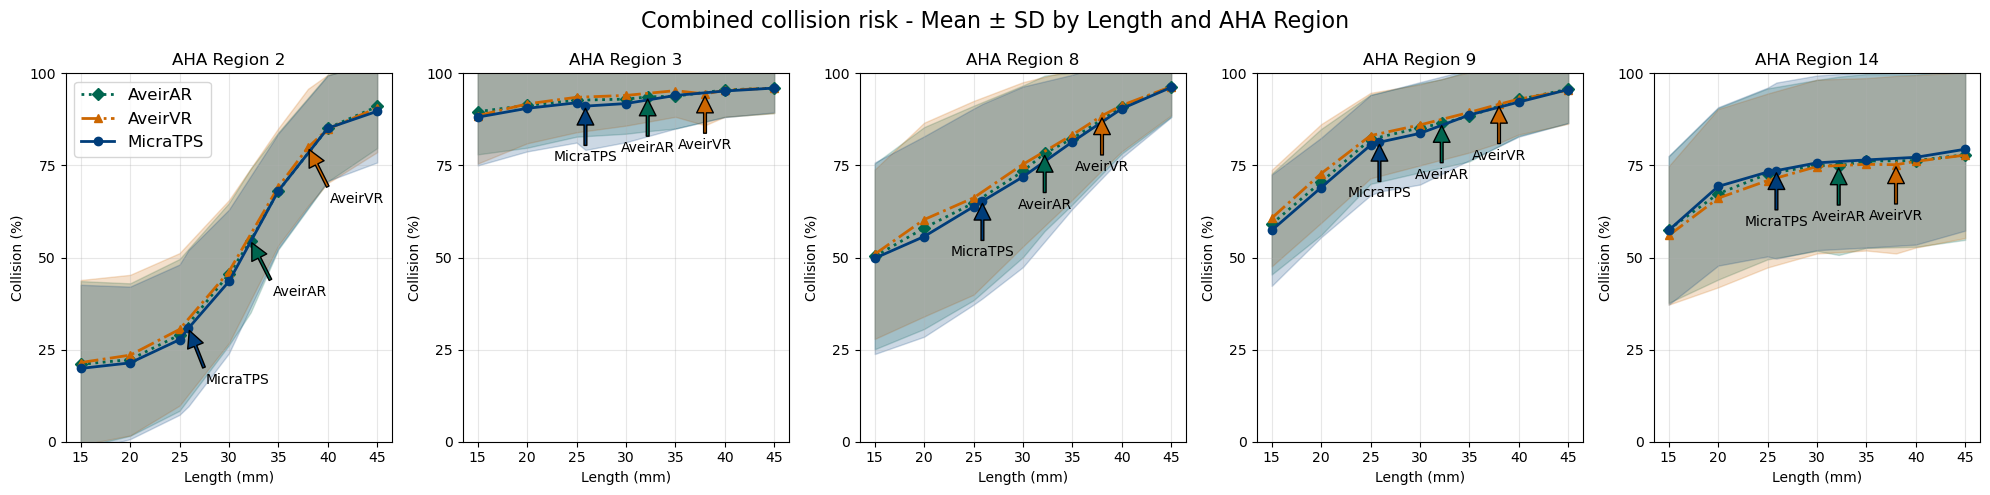


Summary Statistics:


,mean_avg,mean_std,std_avg,std_std
AveirVR_L38_RV_Collision,69.68,15.052096,20.44,3.342813
AveirVR_L38_TV_Collision,20.62,27.543812,14.82,11.190067
AveirVR_L38_PM_Collision,23.98,12.486697,18.34,5.669780
AveirVR_L38_Combined_Collision,85.92,7.238619,14.76,5.401333
AveirVR_L15_RV_Collision,21.84,13.586994,19.12,6.806291
AveirVR_L15_TV_Collision,20.56,27.385587,14.84,10.788624
AveirVR_L15_PM_Collision,21.96,12.421691,15.98,6.003799
AveirVR_L15_Combined_Collision,55.52,21.417040,18.06,4.335712
AveirVR_L20_RV_Collision,29.72,17.332213,22.84,8.454017
AveirVR_L20_TV_Collision,21.02,27.814198,15.22,10.987338


In [ ]:
# analysis PLOT for the line plots

import pandas as pd
import os
import sys
import numpy as np
import matplotlib.pyplot as plt


def read_AHA_csv(merged_df, device, lengths, collision_fields=['Combined_Collision'], diameters=None): 
    main_path = '/data_fast/Work/MS_HF_cohort/images'
    #, RV_Collision, TV_Collision, 'PM_Collision', 'Combined_Collision'
      
 
    for i, length in enumerate(lengths): #, 15, 20, 25, 30, 35, 40, 45]:  #[22, 27, 32, 37, 42]: 
        for collision_field in collision_fields: #['RV_Collision', 'TV_Collision', 'PM_Collision', 'Combined_Collision']: 
            diameter = diameters[i] if diameters is not None else None
            #, RV_Collision, TV_Collision, 'PM_Collision', 'Combined_Collision'
            if collision_field == 'Combined_Collision':
                images_outpath=f'{main_path}/{device}/'
                add_legend=True
            else: 
                images_outpath=f'{main_path}/{device}/{collision_field}/'
                add_legend=False


            csv_outfile=f'{images_outpath}/sum_plots/RV_septum_polar_sum_{device}_L{length}.csv'
            print(f'CSV outfile: {csv_outfile}')
            df= pd.read_csv(csv_outfile)
            #display(df)
            if diameter is not None: 
                label= f'{device}_L{length}_D{diameter:1.1f}_{collision_field}'
            else:     
                label= f'{device}_L{length}_{collision_field}'
                # Create formatted column
            df[label] = df.apply(lambda row: f"{row['mean']:.1f} ± {row['std']:.1f}", axis=1)
            # Subset to AHA_region and formatted column
            df = df[["AHA_region", label]]

            # Merge
            if merged_df is None:
                merged_df = df
            else:
                merged_df = pd.merge(merged_df, df, on="AHA_region", how="outer")
    return merged_df


def extract_mean_std_from_formatted(formatted_str):
    """Extract mean and std from formatted string 'mean ± std'"""
    try:
        parts = formatted_str.split(' ± ')
        mean = float(parts[0])
        std = float(parts[1])
        return mean, std
    except:
        return np.nan, np.nan
    
        under_color = "#4da6ff"
        under_color = "#66b38c"        
        under_color = "#ff9933"


def get_specs(): 
    device_colors = {
        'Micra': '#003d7a', ## '#2596be',
        'MicraTPS': '#003d7a',
        'OtherPallete': '#f4a582', 
        'AveirVR': '#cc6600',  # '#b2182b',
        'AveirAR': '#00664f'  #  '#92c5de'
    }
    device_linestyles = {
        'Micra': '-',
        'MicraTPS': '-',
        'OtherPallete': '--',
        'AveirVR': '-.',
        'AveirAR': ':'
    }
    device_markers = {
        'Micra': 'o',
        'MicraTPS': 'o',
        'OtherPallete': 's',
        'AveirVR': '^',
        'AveirAR': 'D'
    }
    init_lens = {
        'AveirVR': 38,
        'AveirAR': 32.2,
        'MicraTPS': 25.9  # If you use MicraTPS as a device name
    }
    init_diams = {
        'AveirVR': 6.5,
        'AveirAR': 6.5,
        'MicraTPS': 6.7  # If you use MicraTPS as a device name
    }
    return device_colors, device_linestyles, device_markers, init_lens, init_diams
def plot_collision_data_by_aha(merged_df, output_path=None):
    """
    Plot mean and standard deviation over lengths for each AHA region and collision field
    
    Parameters:
    merged_df: DataFrame with formatted collision data
    output_path: Optional path to save plots
    """
    # Extract device names, lengths, and collision fields from column names
    columns = [col for col in merged_df.columns if col != 'AHA region']
    
    # Parse column names to extract components
    data_info = []
    for col in columns:
        parts = col.split('_')
        if len(parts) >= 3:
            device = parts[0]
            length_part = parts[1].replace('L', '')
            
            # Check if there's a diameter component (D followed by number)
            diameter = None
            collision_start_idx = 2
            
            if len(parts) > 3 and parts[2].startswith('D'):
                try:
                    diameter = float(parts[2].replace('D', ''))
                    collision_start_idx = 3
                except ValueError:
                    # If D part can't be converted to float, treat as part of collision_field
                    pass
            
            collision_field = '_'.join(parts[collision_start_idx:])
            
            # Handle device name mapping
            if device == 'Micra': 
                device = 'MicraTPS'
            
            data_info.append({
                'column': col,
                'device': device,
                'length': float(length_part),
                'diameter': diameter,
                'collision_field': collision_field
            })
    # for col in columns:
    #     parts = col.split('_')
    #     if len(parts) >= 3:
    #         device = parts[0]
    #         length = parts[1].replace('L', '')
    #         collision_field = '_'.join(parts[2:])
    #         if device=='Micra': 
    #             device = 'MicraTPS'

    #         data_info.append({
    #             'column': col,
    #             'device': device,
    #             'length': float(length),
    #             'collision_field': collision_field
    #         })
    
    #print(data_info)
    # Convert to DataFrame for easier manipulation
    info_df = pd.DataFrame(data_info)

    # Get unique values
    devices = sorted(info_df['device'].unique())
    collision_fields = sorted(info_df['collision_field'].unique())
    aha_regions = sorted(merged_df['AHA region'].unique())
    
    # Colors for devices
    colors = {'AveirVR': 'red', 'AveirAR': 'blue', 'Micra': 'green'}
    
    # Create plots for each collision field
    for collision_field in ['PM_Collision', 'TV_Collision', 'RV_Collision', 'Combined_Collision']: #collision_fields:
        # First pass: collect all data to determine global y-axis limits
        all_means = []
        all_stds = []
        
        for aha_region in aha_regions:
            region_data = merged_df[merged_df['AHA region'] == aha_region]
            
            for device in devices:
                device_cols = info_df[
                    (info_df['device'] == device) & 
                    (info_df['collision_field'] == collision_field)
                ]['column'].tolist()
                
                for col in device_cols:
                    formatted_val = region_data[col].iloc[0] if len(region_data) > 0 else np.nan
                    
                    if pd.notna(formatted_val):
                        mean, std = extract_mean_std_from_formatted(formatted_val)
                        if not (np.isnan(mean) or np.isnan(std)):
                            all_means.append(mean)
                            all_stds.append(std)
        
        # Calculate global y-axis limits
        if all_means and all_stds:
            all_means = np.array(all_means)
            all_stds = np.array(all_stds)
            y_min = np.min(all_means - all_stds)
            y_max = np.max(all_means + all_stds)
            # Add some padding
            y_range = y_max - y_min
            y_min = max(0, y_min - 0.05 * y_range)  # Don't go below 0
            y_max = y_max + 0.05 * y_range
        else:
            y_min, y_max = 0, 100  # Default range
        
        n_regions = len(aha_regions)
        n_rows = 1  # Single row
        n_cols = n_regions  # One column per AHA region
        
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 5))
        # Handle different subplot configurations
        if n_regions == 1:
            # Single subplot case
            axes = [axes]
        else:
            # Multiple subplots case
            if isinstance(axes, np.ndarray):
                if axes.ndim == 1:
                    # Single row or single column of subplots
                    axes = axes.tolist()
                else:
                    # Multiple rows and columns
                    axes = axes.flatten().tolist()
            else:
                # This shouldn't happen with n_regions > 1, but just in case
                axes = [axes]
        offset=10
        xoffset=0
        if collision_field == 'Combined_Collision': 
            title_str='Combined collision risk'
            offset=-15 # point up = -10, point down = +10 for init_len 
            xoffset=5
        elif collision_field == 'RV_Collision': 
            title_str='RV endocardium collision risk'
            offset=-15
        elif collision_field == 'TV_Collision': 
            title_str='Tricuspid valve structures collision risk'
        elif collision_field == 'PM_Collision': 
            title_str = 'Papillary muscles and moderator band collision risk'
        else: 
            title_str=collision_field

        fig.suptitle(f'{title_str} - Mean ± SD by Length and AHA Region', fontsize=16, y=0.98)
        print(axes[0])
        for i, aha_region in enumerate(aha_regions):
            if aha_region==2 and collision_field == 'Combined_Collision': 
                xoffset=5
            else:
                xoffset=0

            ax = axes[i] if n_regions > 1 else axes[0]
            
            # Get data for this AHA region
            region_data = merged_df[merged_df['AHA region'] == aha_region]
            
            for device in devices:
                # Filter columns for this device and collision field
                device_cols = info_df[
                    (info_df['device'] == device) & 
                    (info_df['collision_field'] == collision_field)
                ]['column'].tolist()
                
                if not device_cols:
                    continue
                
                # Extract lengths and values
                lengths = []
                means = []
                stds = []
                diameters =[]
                for col in device_cols:
                    # Get length from column name
                    length = info_df[info_df['column'] == col]['length'].iloc[0]
                    diameter = info_df[info_df['column'] == col]['diameter'].iloc[0]
                    # Get formatted value
                    formatted_val = region_data[col].iloc[0] if len(region_data) > 0 else np.nan
                    
                    if pd.notna(formatted_val):
                        mean, std = extract_mean_std_from_formatted(formatted_val)
                        if not (np.isnan(mean) or np.isnan(std)):
                            lengths.append(length)
                            if diameter is not None: 
                                diameters.append(diameter)
                            means.append(mean)
                            stds.append(std)

                
                if lengths:  # Only plot if we have data
                    lengths = np.array(lengths)                    
                    means = np.array(means)
                    stds = np.array(stds)
                    if diameter is not None: 
                        diameters = np.array(diameters)
                    
                    # Sort by length
                    sort_idx = np.argsort(lengths)
                    lengths = lengths[sort_idx]
                    means = means[sort_idx]
                    stds = stds[sort_idx]
                    
                    # Plot mean line with error bars
                    color = colors.get(device, 'black')
                    #ax.plot(lengths, means, marker='o', color=color, label=device, linewidth=2)
                    device_colors, device_linestyles, device_markers, init_lens, init_diams=get_specs()
                    
                    

                    if diameter is not None: 
                        ax.plot(diameters, means, label=device, linewidth=2, 
                                color=device_colors.get(device, '#000000'), 
                                linestyle=device_linestyles.get(device, '-'),
                                marker=device_markers.get(device, 'o'))
                        ax.fill_between(diameters, means - stds, means + stds, 
                                        color=device_colors.get(device, '#000000'), alpha=0.2) 
                        # Add arrow at init_len
                        init_len = init_diams.get(device)
                        if init_len is not None and init_len in diameters:
                            idx = np.where(lengths == init_len)[0]
                            if len(idx) > 0:
                                y_val = means[idx[0]]
                                ax.annotate(
                                    device,
                                    xy=(init_len, y_val),
                                    xytext=(init_len+xoffset, y_val +offset),  # Adjust offset as needed
                                    arrowprops=dict(facecolor=device_colors.get(device, '#000000'), shrink=0.05, width=2),
                                    ha='center', color=device_colors.get(device, '#000000'), fontsize=10
                                )
                    else: 
                        ax.plot(lengths, means, label=device, linewidth=2, 
                                color=device_colors.get(device, '#000000'), 
                                linestyle=device_linestyles.get(device, '-'),
                                marker=device_markers.get(device, 'o'))
                        ax.fill_between(lengths, means - stds, means + stds, 
                                        color=device_colors.get(device, '#000000'), alpha=0.2) 
                                    
                        # Add arrow at init_len
                        init_len = init_lens.get(device)
                        if init_len is not None and init_len in lengths:
                            idx = np.where(lengths == init_len)[0]
                            if len(idx) > 0:
                                y_val = means[idx[0]]
                                
                                ax.annotate(
                                    device,
                                    xy=(init_len, y_val),
                                    xytext=(init_len+xoffset, y_val + offset),  # Adjust offset as needed
                                    arrowprops=dict(facecolor=device_colors.get(device, '#000000'), shrink=0.05, width=2),
                                    ha='center', #color=device_colors.get(device, '#000000'), fontsize=10
                                    color='#000000', fontsize=10
                                )
            ax.set_title(f'AHA Region {aha_region}')
            if diameter is not None: 
                ax.set_xlabel('Diameters')
            else: 
                ax.set_xlabel('Length (mm)')
            ax.set_ylabel('Collision (%)')
            ax.set_yticks([0, 25, 50, 75, 100])
            ax.grid(True, alpha=0.3)
            if i == 0: # Only add legend in first plot
                ax.legend(fontsize=12, loc="upper left")
            #ax.axhline(y=50, color='r', linestyle='--', linewidth=2, label="50%% risk of collision")
            # Set the same y-axis limits for all subplots
            ax.set_ylim(0, 100)
        
        # Hide empty subplots
        for i in range(n_regions, len(axes)):
            axes[i].set_visible(False)
        
        plt.tight_layout()
        
        # Save plot if output path provided
        if output_path:
            os.makedirs(output_path, exist_ok=True)
            plt.savefig(f'{output_path}/{collision_field}_by_AHA_region.png', 
                       dpi=300, bbox_inches='tight')
        
        plt.show()

def create_summary_table(merged_df, output_path=None):
    """Create summary statistics table"""
    # Extract numeric data from formatted strings
    numeric_data = {}
    
    for col in merged_df.columns:
        if col != 'AHA region':
            means = []
            stds = []
            for val in merged_df[col]:
                if pd.notna(val):
                    mean, std = extract_mean_std_from_formatted(val)
                    means.append(mean)
                    stds.append(std)
            
            numeric_data[col] = {
                'mean_avg': np.nanmean(means),
                'mean_std': np.nanstd(means),
                'std_avg': np.nanmean(stds),
                'std_std': np.nanstd(stds)
            }
    
    summary_df = pd.DataFrame(numeric_data).T
    
    if output_path:
        summary_df.to_csv(f'{output_path}/summary_statistics.csv')
    
    return summary_df

if __name__ == "__main__":
    # Initialize empty merged DataFrame
    merged_df = None

    devices={
        "Micra": {"D": 6.7, "L": 25.9}, # AV/AV2
        "AveirAR": {"D": 6.5, "L": 32.2}, # atrial Aveir DR device 
        "AveirVR": {"D": 6.5, "L": 38} # Atrial Aveir DR device + 10mm
    }

    for device in ["AveirVR", "AveirAR" , "Micra"]:
        D = devices[device]["D"]
        init_len = devices[device]["L"]
        
        # Calculate original volume
        vol = np.pi * ((D / 2) ** 2) * init_len

        lengths=[init_len, 15, 20, 25, 30, 35, 40, 45] # [22, 27, 32, 37, 42]:
        diameters=[]
        # If we want to keep the same volume, calculate new diameter for each new length
        for length in lengths:
            new_D = np.sqrt(vol / (np.pi * length)) * 2
            diameters.append(new_D)
            print(f"{length:8.0f}    | {new_D:8.3f}")

        coll_fields=[ 'RV_Collision', 'TV_Collision', 'PM_Collision','Combined_Collision']
        #coll_fields=['Combined_Collision']
        merged_df=read_AHA_csv(merged_df, device, lengths, collision_fields=coll_fields) #, diameters=diameters)

    # Rename for output
    merged_df.rename(columns={"AHA_region": "AHA region"}, inplace=True)

    # Sort by AHA region
    merged_df.sort_values("AHA region", inplace=True)
    #display(merged_df)
    #merged_df.to_csv(f'/data_fast/Work/MS_HF_cohort/images/AHA_mapping_summary.csv', index=False)
    #pivot_df = merged_df.set_index("AHA region").T
    #pd.set_option('display.max_rows', None)  # Show all rows in DataFrame display

    #display(pivot_df)
    #pivot_df.to_csv(f'/data_fast/Work/MS_HF_cohort/images/AHA_mapping_summary.csv', index=True)
    ###################################################################################
    # Rename for output
    merged_df.rename(columns={"AHA_region": "AHA region"}, inplace=True)
    
    # Sort by AHA region
    merged_df.sort_values("AHA region", inplace=True)
    
    #display(merged_df)
    #merged_df.to_csv(f'/data_fast/Work/MS_HF_cohort/images/AHA_mapping_summary.csv', index=False)
    
    pivot_df = merged_df.set_index("AHA region").T
    pd.set_option('display.max_rows', None) # Show all rows in DataFrame display
    #display(pivot_df)
    pivot_df.to_csv(f'/data_fast/Work/MS_HF_cohort/images/AHA_mapping_summary.csv', index=True)
    
    
    # NEW: Create plots for collision data
    output_plot_path = '/data_fast/Work/MS_HF_cohort/images/plots'
    plot_collision_data_by_aha(merged_df, output_path=output_plot_path)
    
    # NEW: Create summary statistics
    summary_stats = create_summary_table(merged_df, output_path=output_plot_path)
    print("\nSummary Statistics:")
    display(summary_stats)


In [ ]:
import pandas as pd
import numpy as np

mainpath='/data_fast/Work/MS_HF_cohort/images/'

for device in ['AveirVR', 'AveirAR', 'Micra']: # #
    if device == 'AveirVR':
        init_len= 38
    elif device == 'AveirAR': 
        init_len= 32.2
    elif device == 'Micra': 
        init_len = 25.9
    else: 
        print(f'WARNING - DEVICE: {device} is not AveirVR, AveirAR or Micra')

    lengths=[init_len] #, 15, 20, 25, 30, 35, 40, 45] # [22, 27, 32, 37, 42]:
    for length in lengths:
        all_collision_values = []
        for AHA_region in [2,3,8,9,14]: 
            csv_file=f'{mainpath}/{device}/csv/{AHA_region}_L{length}.csv'
            print(f'CSV file: {csv_file}')  
            df = pd.read_csv(csv_file)            
            print(f'AHA region {AHA_region}: MEAN: {np.mean(df['collision_value']*10):1.1f}%, STD: {10*np.std(df['collision_value']):1.1f}%')
            all_collision_values.extend(df['collision_value'].tolist())

        print(f'All collision values for {device} at length {length}: {np.mean(all_collision_values)*10:1.1f}%, STD: {10*np.std(all_collision_values):1.1f}%')  




CSV file: /data_fast/Work/MS_HF_cohort/images//AveirVR/csv/2_L38.csv
AHA region 2: MEAN: 79.9%, STD: 15.9%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirVR/csv/3_L38.csv
AHA region 3: MEAN: 94.4%, STD: 8.5%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirVR/csv/8_L38.csv
AHA region 8: MEAN: 88.5%, STD: 14.8%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirVR/csv/9_L38.csv
AHA region 9: MEAN: 91.6%, STD: 10.5%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirVR/csv/14_L38.csv
AHA region 14: MEAN: 75.2%, STD: 24.1%
All collision values for AveirVR at length 38: 85.0%, STD: 18.2%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirAR/csv/2_L32.2.csv
AHA region 2: MEAN: 54.6%, STD: 19.5%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirAR/csv/3_L32.2.csv
AHA region 3: MEAN: 93.6%, STD: 9.3%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirAR/csv/8_L32.2.csv
AHA region 8: MEAN: 78.3%, STD: 21.1%
CSV file: /data_fast/Work/MS_HF_cohort/images//AveirAR/csv/9_L32.2.csv
AH

In [ ]:
# MAKE TABLE for Table2

#           AHA regions
# Micra TPS
# Aveir AR 
# Aveir VR

